# **EXPLORATORY DATA ANALYSIS**

## **Library**

In [2]:
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import matplotlib.ticker as mticker
import seaborn as sns

from pathlib import Path

In [3]:
data_ind = pd.read_excel(r"C:\Users\Salim\Kuliah\SKRIPSI\Data\data_input.xlsx", sheet_name="Indonesia")
data_ind

,date,region,harvested_area,paddy_prod
0,2019-01-01,Indonesia,414629.85,2037525.40
1,2019-02-01,Indonesia,732372.07,3631559.37
2,2019-03-01,Indonesia,1718387.76,9168951.06
3,2019-04-01,Indonesia,1684543.60,8937443.56
4,2019-05-01,Indonesia,916201.33,4367308.27
...,...,...,...,...
79,2025-08-01,Indonesia,1112647.40,5625860.12
80,2025-09-01,Indonesia,1134430.58,5969147.26
81,2025-10-01,Indonesia,862190.10,4738398.46
82,2025-11-01,Indonesia,571338.94,3195693.55


In [4]:
data_ind.info()

<class 'pandas.DataFrame'>
RangeIndex: 84 entries, 0 to 83
Data columns (total 4 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   date            84 non-null     datetime64[us]
 1   region          84 non-null     str           
 2   harvested_area  84 non-null     float64       
 3   paddy_prod      84 non-null     float64       
dtypes: datetime64[us](1), float64(2), str(1)
memory usage: 2.8 KB


In [5]:
# summary statistics
data_ind.describe()

,date,harvested_area,paddy_prod
count,84,8.400000e+01,8.400000e+01
mean,2022-06-16 14:17:08.571428,8.721841e+05,4.592242e+06
min,2019-01-01 00:00:00,5.756287e+04,1.516040e+06
25%,2020-09-23 12:00:00,5.664339e+05,3.215838e+06
50%,2022-06-16 00:00:00,8.287987e+05,4.267132e+06
75%,2024-03-08 18:00:00,1.040968e+06,5.494257e+06
max,2025-12-01 00:00:00,1.855764e+06,9.768002e+06
std,NaN,4.057375e+05,2.124858e+06


## **National Visualization**

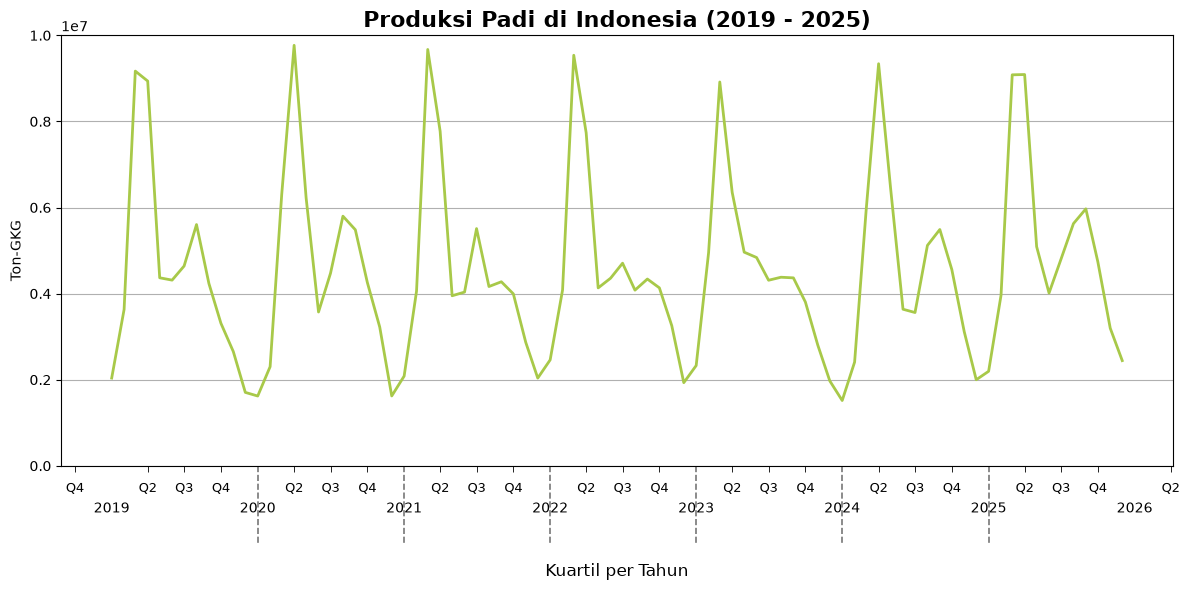

In [6]:
# paddy_prod visualization
plt.figure(figsize=(12, 6))

ax = sns.lineplot(data=data_ind, x='date', y='paddy_prod',
                  linewidth=2,
                  color='#A8C949')

# Nested x-axis labels: tahun (baris bawah) dan kuartil (baris atas)
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
ax.xaxis.set_minor_locator(mdates.MonthLocator(bymonth=[1, 4, 7, 10]))
ax.xaxis.set_minor_formatter(mticker.FuncFormatter(
    lambda x, pos: f'Q{((mdates.num2date(x).month - 1) // 3) + 1}'
))
ax.tick_params(axis='x', which='major', pad=26, length=0, labelsize=10)
ax.tick_params(axis='x', which='minor', pad=8, length=4, labelsize=9)
# Garis pembatas antar tahun
year_boundaries = pd.date_range(
    start=data_ind['date'].min().replace(month=1, day=1),
    end=data_ind['date'].max().replace(month=1, day=1),
    freq='YS'
)[1:]
for boundary in year_boundaries:
    ax.plot([boundary, boundary], [0, -0.18],
            transform=ax.get_xaxis_transform(), color='#555555',
            linewidth=1.2, linestyle='--', alpha=0.8, clip_on=False)
plt.title('Produksi Padi di Indonesia (2019 - 2025)', fontsize=16, fontweight='bold')
plt.grid(True, axis='y')
plt.ylim(0, 10000000)
plt.xlabel('Kuartil per Tahun', fontsize=12, labelpad=34)
plt.ylabel('Ton-GKG')
plt.tight_layout()
plt.show()

## **Data Per Province**

In [7]:
DATA_FULL_PATH = (
    Path.cwd()
    / "data"
    / "processed"
    / "final_province_dataset.csv"
)

if not DATA_FULL_PATH.exists():
    DATA_FULL_PATH = (
        Path.cwd().parent
        / "data"
        / "processed"
        / "final_province_dataset.csv"
    )

data_full = pd.read_csv(
    DATA_FULL_PATH,
    parse_dates=["date"]
)

data_full.head()

,province,date,PRECTOTCORR,RH2M,T2M,n_regions,harvested_area,paddy_prod
0,Banten,2019-01-01,12.66500,85.10625,26.52625,8,5731.41,28998.90
1,Banten,2019-02-01,9.09000,84.01750,26.84875,8,12005.08,59117.51
2,Banten,2019-03-01,9.03625,84.02875,26.65875,8,40604.37,208921.49
3,Banten,2019-04-01,8.65125,84.35500,27.40375,8,81452.89,411752.33
4,Banten,2019-05-01,5.30875,82.88375,27.34875,8,24099.06,108998.36


In [8]:
data_full.info()

<class 'pandas.DataFrame'>
RangeIndex: 420 entries, 0 to 419
Data columns (total 8 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   province        420 non-null    str           
 1   date            420 non-null    datetime64[us]
 2   PRECTOTCORR     420 non-null    float64       
 3   RH2M            420 non-null    float64       
 4   T2M             420 non-null    float64       
 5   n_regions       420 non-null    int64         
 6   harvested_area  420 non-null    float64       
 7   paddy_prod      420 non-null    float64       
dtypes: datetime64[us](1), float64(5), int64(1), str(1)
memory usage: 26.4 KB


In [9]:
sns.set_theme(
    style="whitegrid",
    context="paper",
    font_scale=1.15
)

FIG_DIR = Path("../results/figures/eda")
FIG_DIR.mkdir(parents=True, exist_ok=True)

data_full = data_full.sort_values(["province", "date"]).reset_index(drop=True)

data_full["month"] = data_full["date"].dt.month
data_full["year"] = data_full["date"].dt.year

province_order = [
    "Banten",
    "DI Yogyakarta",
    "Jawa Barat",
    "Jawa Tengah",
    "Jawa Timur",
]

data_full["province"] = pd.Categorical(
    data_full["province"],
    categories=province_order,
    ordered=True
)

data_full.head()

,province,date,PRECTOTCORR,RH2M,T2M,n_regions,harvested_area,paddy_prod,month,year
0,Banten,2019-01-01,12.66500,85.10625,26.52625,8,5731.41,28998.90,1,2019
1,Banten,2019-02-01,9.09000,84.01750,26.84875,8,12005.08,59117.51,2,2019
2,Banten,2019-03-01,9.03625,84.02875,26.65875,8,40604.37,208921.49,3,2019
3,Banten,2019-04-01,8.65125,84.35500,27.40375,8,81452.89,411752.33,4,2019
4,Banten,2019-05-01,5.30875,82.88375,27.34875,8,24099.06,108998.36,5,2019


### **Descriptive Statistic** 

In [10]:
summary = (
    data_full.groupby("province", observed=True)
      .agg(
          production_mean=("paddy_prod", "mean"),
          production_std=("paddy_prod", "std"),
          production_min=("paddy_prod", "min"),
          production_max=("paddy_prod", "max"),
          harvested_area_mean=("harvested_area", "mean"),
          harvested_area_std=("harvested_area", "std"),
          rainfall_mean=("PRECTOTCORR", "mean"),
          rainfall_std=("PRECTOTCORR", "std"),
      )
)

summary["production_cv"] = (
    summary["production_std"] / summary["production_mean"]
)

summary["harvested_area_cv"] = (
    summary["harvested_area_std"] / summary["harvested_area_mean"]
)

summary["rainfall_cv"] = (
    summary["rainfall_std"] / summary["rainfall_mean"]
)

summary.round(3)

,production_mean,production_std,production_min,production_max,harvested_area_mean,harvested_area_std,rainfall_mean,rainfall_std,production_cv,harvested_area_cv,rainfall_cv
province,,,,,,,,,,,
Banten,137245.555,107339.124,13344.66,446933.38,26898.956,20151.648,7.082,4.251,0.782,0.749,0.600
DI Yogyakarta,44163.802,34333.610,8249.70,155051.86,8810.771,7558.966,7.287,4.606,0.777,0.858,0.632
Jawa Barat,769554.748,350681.347,151954.27,1696126.86,133887.574,61475.574,8.237,4.606,0.456,0.459,0.559
Jawa Tengah,778564.147,513071.492,161284.80,2449941.28,141902.706,89526.044,6.925,4.303,0.659,0.631,0.621
Jawa Timur,812631.341,524432.798,266300.36,2287460.65,146979.202,92020.382,6.253,5.115,0.645,0.626,0.818


### **EDA**

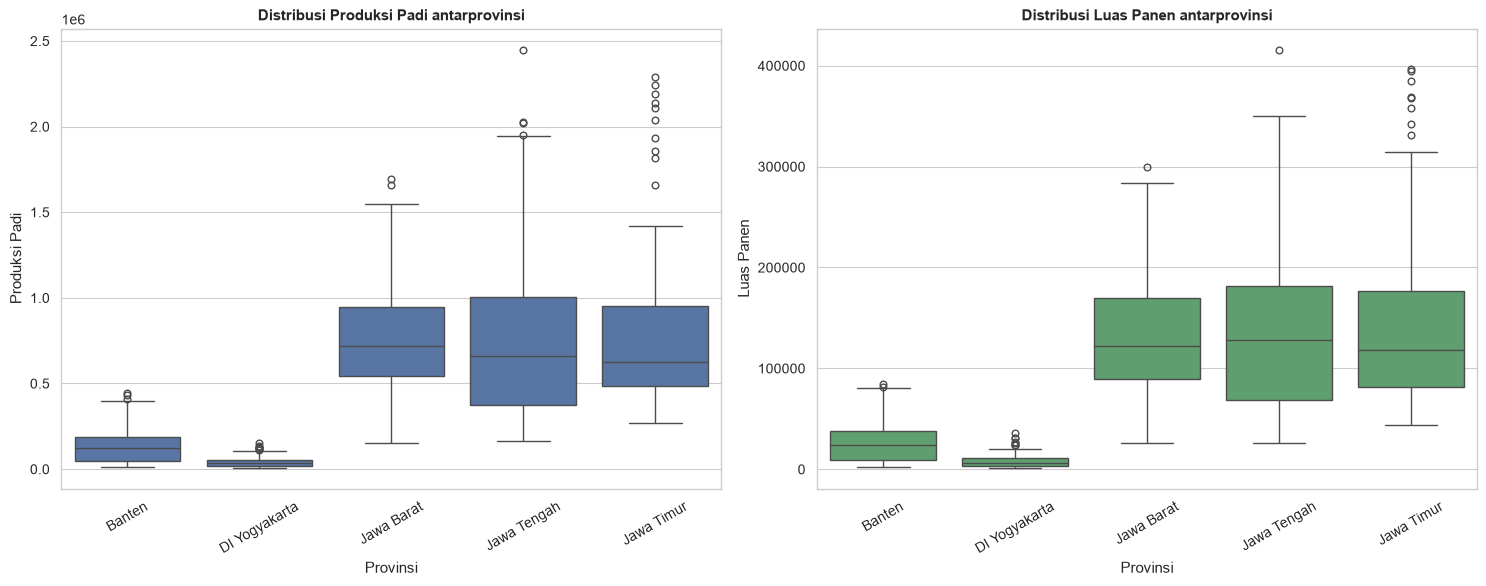

In [11]:
fig, axes = plt.subplots(
    1,
    2,
    figsize=(15, 6)
)

sns.boxplot(
    data=data_full,
    x="province",
    y="paddy_prod",
    order=province_order,
    color="#4C72B0",
    ax=axes[0]
)

axes[0].set_title(
    "Distribusi Produksi Padi antarprovinsi",
    fontweight="bold"
)
axes[0].set_xlabel("Provinsi")
axes[0].set_ylabel("Produksi Padi")
axes[0].tick_params(axis="x", rotation=30)

sns.boxplot(
    data=data_full,
    x="province",
    y="harvested_area",
    order=province_order,
    color="#55A868",
    ax=axes[1]
)

axes[1].set_title(
    "Distribusi Luas Panen antarprovinsi",
    fontweight="bold"
)
axes[1].set_xlabel("Provinsi")
axes[1].set_ylabel("Luas Panen")
axes[1].tick_params(axis="x", rotation=30)

plt.tight_layout()

plt.savefig(
    FIG_DIR / "province_production_area_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

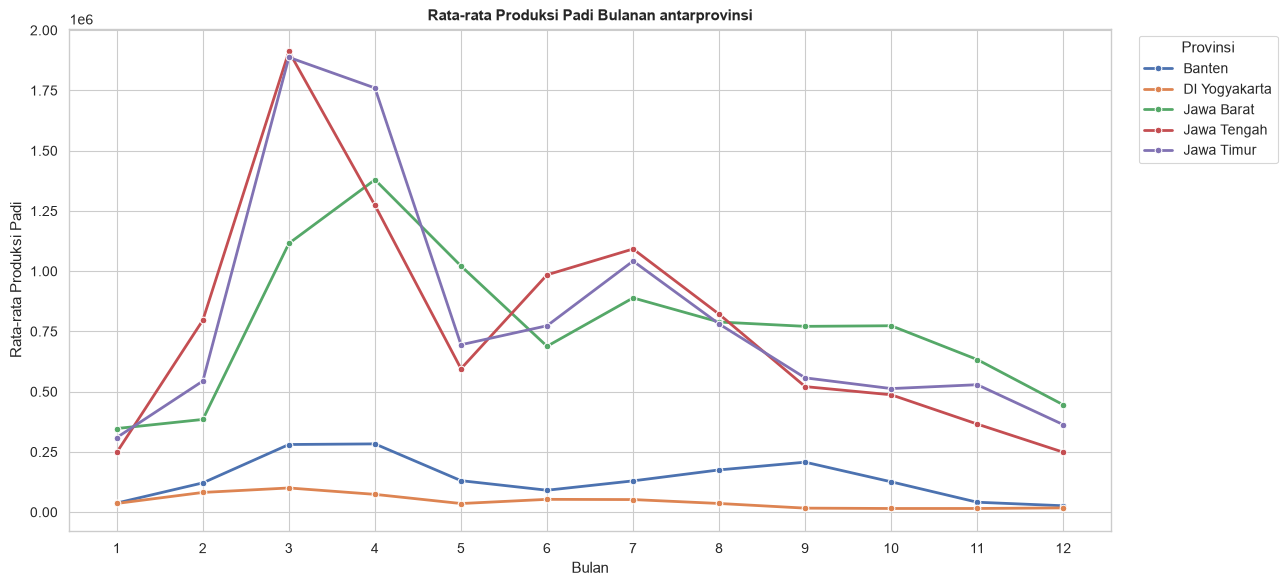

In [12]:
monthly_production = (
    data_full
    .groupby(["province", "month"], observed=True)["paddy_prod"]
    .mean()
    .reset_index()
)

plt.figure(figsize=(13, 6))

sns.lineplot(
    data=monthly_production,
    x="month",
    y="paddy_prod",
    hue="province",
    hue_order=province_order,
    marker="o",
    linewidth=2
)

plt.title(
    "Rata-rata Produksi Padi Bulanan antarprovinsi",
    fontweight="bold"
)
plt.xlabel("Bulan")
plt.ylabel("Rata-rata Produksi Padi")
plt.xticks(range(1, 13))
plt.legend(
    title="Provinsi",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()

plt.savefig(
    FIG_DIR / "monthly_production_by_province.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

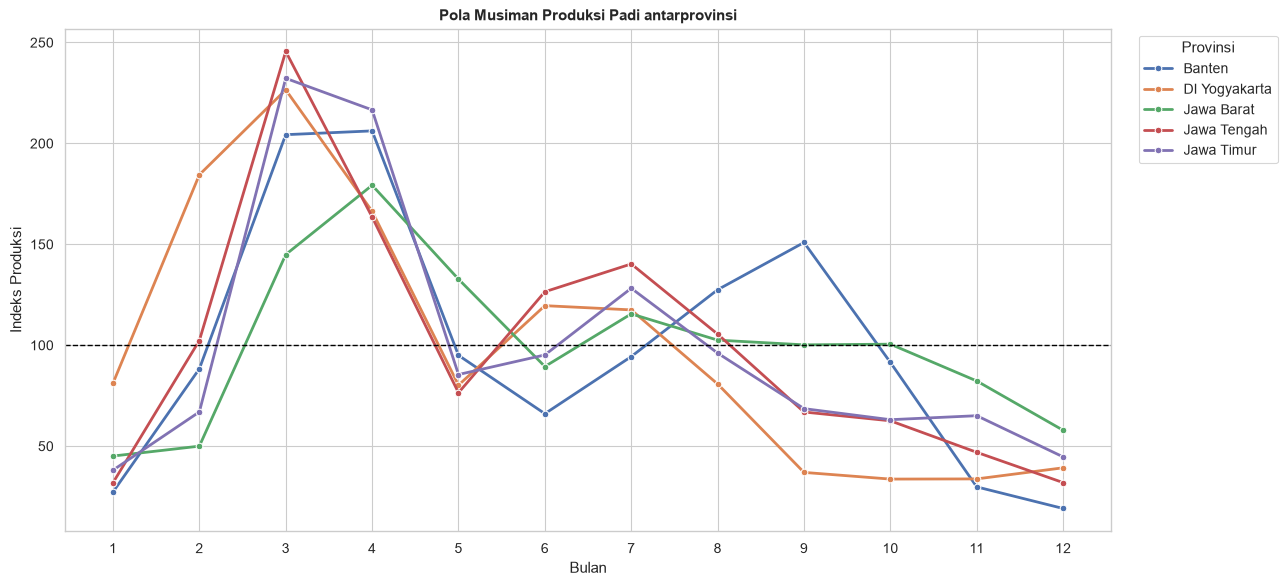

In [13]:
seasonal_production = (
    data_full
    .groupby(["province", "month"], observed=True)["paddy_prod"]
    .mean()
    .reset_index()
)

seasonal_production["production_index"] = (
    seasonal_production["paddy_prod"]
    /
    seasonal_production
    .groupby("province")["paddy_prod"]
    .transform("mean")
    * 100
)

plt.figure(figsize=(13, 6))

sns.lineplot(
    data=seasonal_production,
    x="month",
    y="production_index",
    hue="province",
    hue_order=province_order,
    marker="o",
    linewidth=2
)

plt.axhline(
    100,
    color="black",
    linestyle="--",
    linewidth=1
)

plt.title(
    "Pola Musiman Produksi Padi antarprovinsi",
    fontweight="bold"
)
plt.xlabel("Bulan")
plt.ylabel("Indeks Produksi")
plt.xticks(range(1, 13))
plt.legend(
    title="Provinsi",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()

plt.savefig(
    FIG_DIR / "seasonal_production_index.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

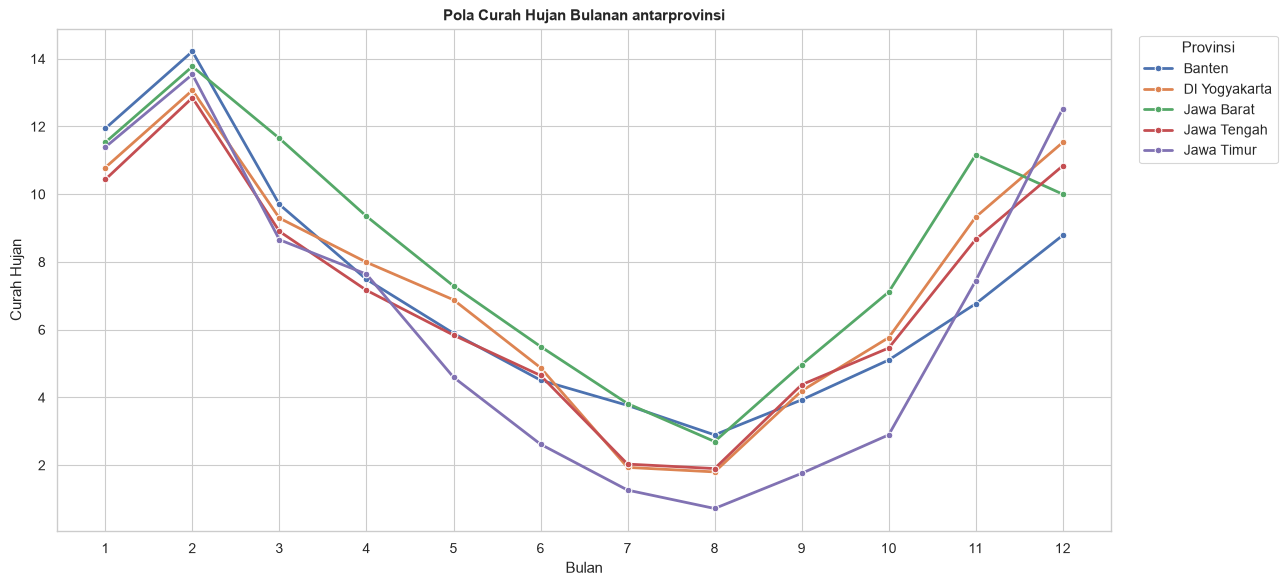

In [14]:
monthly_rainfall = (
    data_full
    .groupby(["province", "month"], observed=True)["PRECTOTCORR"]
    .mean()
    .reset_index()
)

plt.figure(figsize=(13, 6))

sns.lineplot(
    data=monthly_rainfall,
    x="month",
    y="PRECTOTCORR",
    hue="province",
    hue_order=province_order,
    marker="o",
    linewidth=2
)

plt.title(
    "Pola Curah Hujan Bulanan antarprovinsi",
    fontweight="bold"
)
plt.xlabel("Bulan")
plt.ylabel("Curah Hujan")
plt.xticks(range(1, 13))
plt.legend(
    title="Provinsi",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()

plt.savefig(
    FIG_DIR / "monthly_rainfall_by_province.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

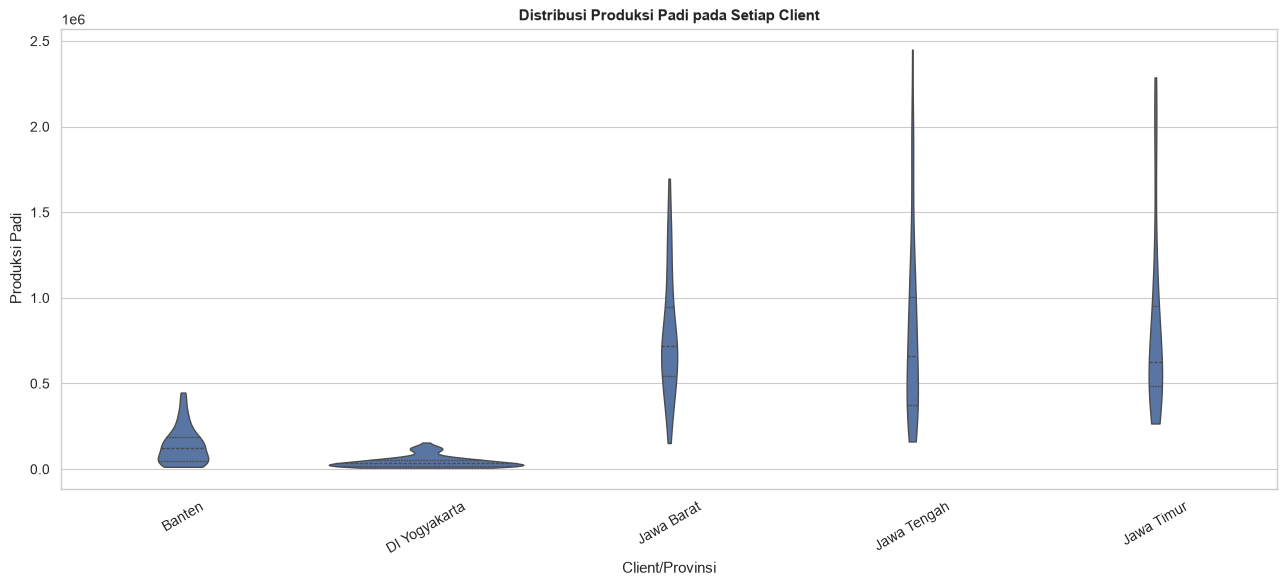

In [15]:
plt.figure(figsize=(13, 6))

sns.violinplot(
    data=data_full,
    x="province",
    y="paddy_prod",
    order=province_order,
    inner="quartile",
    cut=0,
    color="#4C72B0"
)

plt.title(
    "Distribusi Produksi Padi pada Setiap Client",
    fontweight="bold"
)
plt.xlabel("Client/Provinsi")
plt.ylabel("Produksi Padi")
plt.xticks(rotation=30)

plt.tight_layout()

plt.savefig(
    FIG_DIR / "client_production_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

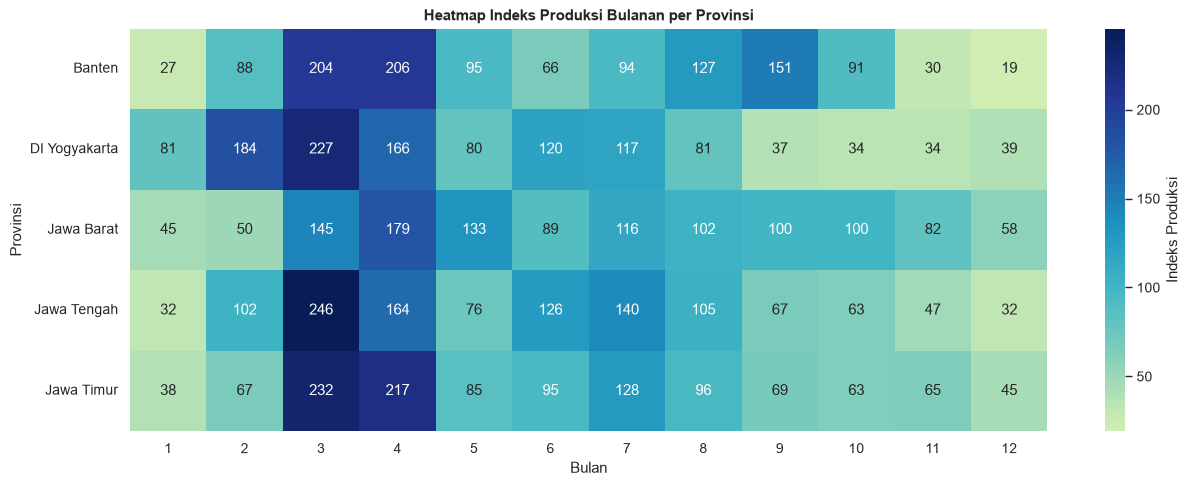

In [16]:
production_heatmap = (
    seasonal_production
    .pivot(
        index="province",
        columns="month",
        values="production_index"
    )
    .reindex(province_order)
)

plt.figure(figsize=(13, 5))

sns.heatmap(
    production_heatmap,
    annot=True,
    fmt=".0f",
    cmap="YlGnBu",
    center=100,
    cbar_kws={
        "label": "Indeks Produksi"
    }
)

plt.title(
    "Heatmap Indeks Produksi Bulanan per Provinsi",
    fontweight="bold"
)
plt.xlabel("Bulan")
plt.ylabel("Provinsi")

plt.tight_layout()

plt.savefig(
    FIG_DIR / "production_seasonality_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Heterogenitas dan Non-IID Data

Setiap provinsi diperlakukan sebagai client yang memiliki data lokal.
Meskipun seluruh client memiliki struktur variabel dan periode pengamatan
yang sama, distribusi data antarclient tidak harus identik.

Perbedaan luas lahan pertanian, kapasitas produksi, kondisi geografis,
pola curah hujan, temperatur, serta kalender tanam menyebabkan setiap
provinsi memiliki skala produksi dan pola musiman yang berbeda.

Secara formal, distribusi data pada client ke-k dapat dituliskan sebagai
$P_k(X, Y)$. Data dikatakan non-IID ketika distribusi antarclient berbeda,
yaitu:

$P_k(X, Y) \ne P_j(X, Y)$

untuk dua client k dan j yang berbeda.

Perbedaan distribusi tersebut dapat diamati melalui variasi rata-rata,
rentang, varians, serta pola musiman produksi, luas panen, dan curah hujan
antarprovinsi. Visualisasi ini memberikan indikasi deskriptif bahwa data
yang digunakan memiliki karakteristik heterogen dan tidak dapat secara
langsung diasumsikan berasal dari satu distribusi yang sama.

In [17]:
### Pemeriksaan Variabel, Korelasi, dan Perbandingan `paddy_prod` vs `harvested_area`

# Scan nama variabel, tipe data, dan jumlah nilai yang tersedia.
variable_scan = pd.DataFrame({
    "variable": data_full.columns,
    "dtype": data_full.dtypes.astype(str).values,
    "non_null": data_full.notna().sum().values,
    "missing": data_full.isna().sum().values,
})
display(variable_scan)

target_variables = ["paddy_prod", "harvested_area"]
missing_variables = [
    variable for variable in target_variables
    if variable not in data_full.columns
]
if missing_variables:
    raise KeyError(f"Variabel tidak ditemukan: {missing_variables}")

comparison_data = data_full[target_variables].apply(
    pd.to_numeric, errors="coerce"
).dropna()
print(f"Jumlah observasi valid untuk pengujian: {len(comparison_data)}")

,variable,dtype,non_null,missing
0,province,category,420,0
1,date,datetime64[us],420,0
2,PRECTOTCORR,float64,420,0
3,RH2M,float64,420,0
4,T2M,float64,420,0
5,n_regions,int64,420,0
6,harvested_area,float64,420,0
7,paddy_prod,float64,420,0
8,month,int32,420,0
9,year,int32,420,0


Jumlah observasi valid untuk pengujian: 420


In [18]:
from scipy.stats import pearsonr, spearmanr

# Uji Pearson mengukur hubungan linear; Spearman mengukur hubungan
# monotonik dan lebih tahan terhadap pencilan/non-normalitas.
pearson_r, pearson_p = pearsonr(
    comparison_data["harvested_area"],
    comparison_data["paddy_prod"]
)
spearman_rho, spearman_p = spearmanr(
    comparison_data["harvested_area"],
    comparison_data["paddy_prod"]
)

correlation_results = pd.DataFrame({
    "test": ["Pearson", "Spearman"],
    "correlation": [pearson_r, spearman_rho],
    "p_value": [pearson_p, spearman_p],
})
display(correlation_results.round({"correlation": 4, "p_value": 6}))

alpha = 0.05
print(
    "Interpretasi: hubungan dianggap signifikan pada taraf 5% jika p-value < "
    f"{alpha}."
)

,test,correlation,p_value
0,Pearson,0.9900,0.0
1,Spearman,0.9869,0.0


Interpretasi: hubungan dianggap signifikan pada taraf 5% jika p-value < 0.05.


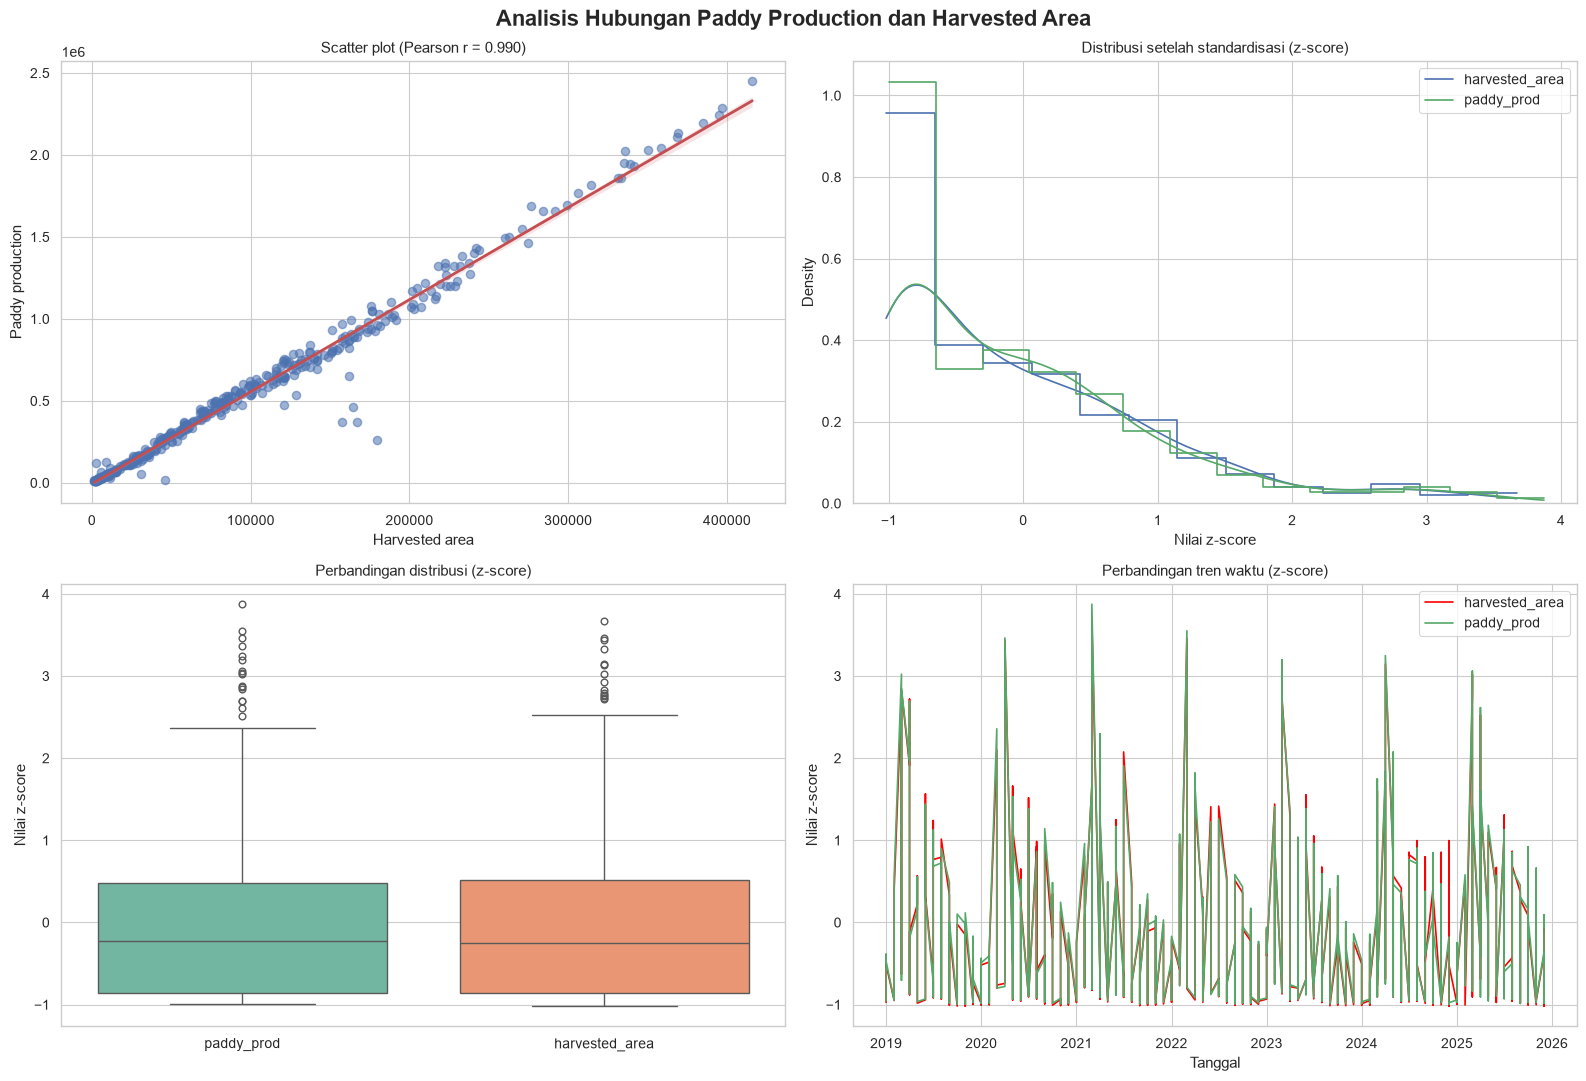

In [20]:
fig, axes = plt.subplots(2, 2, figsize=(16, 11))

# 1. Scatter plot dan garis regresi untuk melihat hubungan langsung.
sns.regplot(
    data=comparison_data,
    x="harvested_area",
    y="paddy_prod",
    scatter_kws={"alpha": 0.55, "s": 35},
    line_kws={"color": "#C44E52", "linewidth": 2},
    ax=axes[0, 0]
)
axes[0, 0].set_title(f"Scatter plot (Pearson r = {pearson_r:.3f})")
axes[0, 0].set_xlabel("Harvested area")
axes[0, 0].set_ylabel("Paddy production")

# 2. Distribusi kedua variabel dengan standardisasi agar skala dapat dibandingkan.
comparison_z = (comparison_data - comparison_data.mean()) / comparison_data.std()
sns.histplot(comparison_z["harvested_area"], color="#4C72B0",
             label="harvested_area", kde=True, stat="density",
             element="step", fill=False, ax=axes[0, 1])
sns.histplot(comparison_z["paddy_prod"], color="#55A868",
             label="paddy_prod", kde=True, stat="density",
             element="step", fill=False, ax=axes[0, 1])
axes[0, 1].set_title("Distribusi setelah standardisasi (z-score)")
axes[0, 1].set_xlabel("Nilai z-score")
axes[0, 1].legend()

# 3. Boxplot standardisasi untuk membandingkan pusat dan sebaran data.
comparison_long = comparison_z.melt(
    var_name="variable", value_name="z_score"
)
sns.boxplot(data=comparison_long, x="variable", y="z_score",
            hue="variable", legend=False, palette="Set2",
            ax=axes[1, 0])
axes[1, 0].set_title("Perbandingan distribusi (z-score)")
axes[1, 0].set_xlabel("")
axes[1, 0].set_ylabel("Nilai z-score")

# 4. Jika tersedia, tampilkan tren waktu kedua variabel pada skala standar.
if "date" in data_full.columns:
    trend_data = data_full[["date"] + target_variables].copy()
    trend_data["date"] = pd.to_datetime(trend_data["date"])
    trend_data = trend_data.sort_values("date")
    trend_z = trend_data[target_variables].apply(
        lambda column: (column - column.mean()) / column.std()
    )
    axes[1, 1].plot(trend_data["date"], trend_z["harvested_area"],
                    label="harvested_area", color="red")
    axes[1, 1].plot(trend_data["date"], trend_z["paddy_prod"],
                    label="paddy_prod", color="#55A868")
    axes[1, 1].set_title("Perbandingan tren waktu (z-score)")
    axes[1, 1].set_xlabel("Tanggal")
    axes[1, 1].set_ylabel("Nilai z-score")
    axes[1, 1].legend()
else:
    axes[1, 1].axis("off")
    axes[1, 1].text(0.5, 0.5, "Kolom date tidak tersedia",
                    ha="center", va="center")

fig.suptitle("Analisis Hubungan Paddy Production dan Harvested Area",
             fontsize=16, fontweight="bold")
plt.tight_layout()
plt.savefig(FIG_DIR / "paddy_prod_vs_harvested_area.png",
            dpi=300, bbox_inches="tight")
plt.show()

11
